# Super-Convergence на MNIST и CIFAR-10

В части I воспроизводим эксперимент LeNet из таблицы 2 статьи
[Smith и Topin, Super-Convergence, v3](https://arxiv.org/html/1708.07120v3).

| Режим | Эпохи | Accuracy авторов |
|---|---:|---:|
| Baseline с inverse decay | 85 | 99,03 ± 0,04% |
| 1cycle | 12 | 99,25 ± 0,03% |

Это ориентиры из статьи. Собственные результаты появятся после обучения.
Также посмотрим на baseline после 12 эпох, чтобы сравнить одинаковые бюджеты.

В части II добавлен CIFAR-10 с ResNet-56. По умолчанию выполняются обе части.
CIFAR использует отдельные настройки, checkpoints и архив; подробности ниже в части II.

**Как запустить:** загрузите ноутбук в Colab, включите GPU и выполните все ячейки.
По умолчанию используем три seed и сохраняем результаты в Google Drive.
В Kaggle нужно включить Internet для загрузки MNIST.

`MODE = "smoke"` запускает короткую проверку на части данных. Для отчёта нужен `MODE = "full"`.
Эта версия использует новую папку `superconvergence_mnist_v3`. Checkpoints предыдущего ноутбука
имеют другой формат, старые результаты остаются в прежней папке.


## 1. Импорты

Используем PyTorch для обучения, pandas для таблиц и Matplotlib для графиков.
Эти библиотеки обычно уже есть в Colab. Автоматически обновлять PyTorch не требуется.


In [ ]:
import os
import json
import math
import platform
import random
import shutil
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from torch import nn
from torchvision.datasets import MNIST


## 2. Настройки запуска

`SEEDS = [0, 1, 2]` означает шесть обучений. Для одного повтора можно оставить `[0]`,
но тогда стандартное отклонение посчитать не получится.
Если меняете код или настройки эксперимента, задайте новое `EXPERIMENT_NAME`.


In [ ]:
MODE = "full"  # "smoke" для короткой проверки
SEEDS = [0, 1, 2]
DEVICE = "auto"  # GPU, если доступен; иначе CPU
CPU_THREADS = 2

EXPERIMENT_NAME = "superconvergence_mnist_v3"
SAVE_TO_DRIVE = True
DOWNLOAD_ZIP = True


In [ ]:
def experiment_config(mode="full", seeds=(0, 1, 2)):
    """Настройки из таблицы 2 и явно выбранные детали нашего эксперимента."""
    config = {
        "mode": mode,
        "seeds": list(seeds),
        "batch_size": 512,
        "eval_batch_size": 1024,
        "baseline_epochs": 85,
        "cycle_epochs": 12,
        "cycle_half_epochs": 5,
        "base_lr": 0.01,
        "max_lr": 0.1,
        "final_lr": 1e-5,             # Наш выбор для конца последней фазы
        "base_momentum": 0.9,
        "min_momentum": 0.8,
        "max_momentum": 0.95,
        "weight_decay": 5e-4,
        "inv_gamma": 1e-4,
        "inv_power": 0.75,
    }
    if mode == "smoke":
        config.update(baseline_epochs=3, cycle_epochs=3, cycle_half_epochs=1)
    return config

config = experiment_config(MODE, SEEDS)
pd.Series(config, name="Настройки")


## 3. Папка с результатами

В Colab подключаем Drive, чтобы checkpoints пережили удаление среды выполнения.
При первом запуске потребуется авторизация. Без Drive Colab хранит результаты только внутри сессии.
В конце ноутбук собирает архив для скачивания.


In [ ]:
in_colab = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

if in_colab and SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    results_root = Path("/content/drive/MyDrive/EffNN")
elif in_colab:
    results_root = Path("/content/EffNN")
elif Path("/kaggle/working").exists():
    results_root = Path("/kaggle/working/EffNN")
else:
    results_root = Path.cwd() / "EffNN_results"

output_dir = results_root / EXPERIMENT_NAME / MODE
output_dir.mkdir(parents=True, exist_ok=True)

# MNIST скачиваем на локальный диск, чтобы не читать данные из Drive на каждом запуске.
if in_colab:
    data_dir = Path("/content/mnist_data")
elif Path("/kaggle/working").exists():
    data_dir = Path("/kaggle/working/mnist_data")
else:
    data_dir = Path.cwd() / "mnist_data"

print("Папка с результатами:", output_dir)


## 4. Воспроизводимость и устройство

Фиксируем генераторы случайных чисел и используем детерминированные операции в float32.
Одинаковый seed даст одинаковые начальные веса и порядок batches для двух режимов.


In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def configure_device(device_name="auto", cpu_threads=2):
    if device_name == "auto":
        device_name = "cuda" if torch.cuda.is_available() else "cpu"

    torch.set_num_threads(cpu_threads)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    return torch.device(device_name)


def describe_environment(device):
    return {
        "python": platform.python_version(),
        "torch": str(torch.__version__),
        "torchvision": str(torchvision.__version__),
        "numpy": np.__version__,
        "platform": platform.platform(),
        "device": str(device),
        "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
        "cuda": torch.version.cuda,
        "cudnn": torch.backends.cudnn.version(),
        "cpu_threads": torch.get_num_threads(),
    }


def synchronize(device):
    """Дождаться вычислений GPU перед измерением времени."""
    if device.type == "cuda":
        torch.cuda.synchronize(device)


In [ ]:
device = configure_device(DEVICE, CPU_THREADS)
environment = describe_environment(device)
display(pd.Series(environment, name="Среда выполнения"))
if device.type == "cpu":
    print("GPU недоступен. Полный эксперимент на CPU может занять больше времени.")

# Сохраняем параметры и список сессий для будущего отчёта.
config_path = output_dir / "config.json"
if config_path.exists():
    previous_config = json.loads(config_path.read_text())
    assert previous_config == config, "Поменяйте EXPERIMENT_NAME для новых настроек."
config_path.write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

sessions_path = output_dir / "sessions.json"
sessions = json.loads(sessions_path.read_text()) if sessions_path.exists() else []
sessions.append({"started_at": datetime.now(timezone.utc).isoformat(), **environment})
sessions_path.write_text(json.dumps(sessions, ensure_ascii=False, indent=2), encoding="utf-8")


## 5. Данные

Полный MNIST содержит 60 000 обучающих и 10 000 тестовых изображений.
Пиксели делим на 256, как в исходном примере Caffe. Аугментации не используем.

Функция возвращает две пары тензоров. У изображений форма `[N, 1, 28, 28]`, у меток `[N]`.
Пока держим данные в RAM, на GPU будем переносить отдельные batches.


In [ ]:
def load_mnist(data_dir, mode="full", download=True):
    """Вернуть train и test, каждый как пару (images, labels).

    images: float32 [N, 1, 28, 28], labels: int64 [N]. Данные остаются на CPU.
    """
    train_dataset = MNIST(data_dir, train=True, download=download)
    test_dataset = MNIST(data_dir, train=False, download=download)

    train_size, test_size = (60000, 10000) if mode == "full" else (2048, 1024)
    train_images = train_dataset.data[:train_size, None].float() / 256
    test_images = test_dataset.data[:test_size, None].float() / 256
    train_labels = train_dataset.targets[:train_size]
    test_labels = test_dataset.targets[:test_size]

    return (train_images, train_labels), (test_images, test_labels)


In [ ]:
train_data, test_data = load_mnist(data_dir, MODE)
train_images, train_labels = train_data
print("Train:", train_images.shape, train_labels.shape)
print("Test:", test_data[0].shape, test_data[1].shape)

steps_per_epoch = math.ceil(len(train_labels) / config["batch_size"])
total_epochs = len(SEEDS) * (config["baseline_epochs"] + config["cycle_epochs"])
print("Шагов на эпоху:", steps_per_epoch)
print("Суммарное число эпох:", total_epochs)


## 6. Модель

Берём LeNet из [примера BVLC Caffe](https://github.com/BVLC/caffe/blob/master/examples/mnist/lenet_train_test.prototxt).
Авторы ссылаются на поставляемую с Caffe архитектуру и её гиперпараметры в разделе 5.1.
В этой реализации ReLU есть только между полносвязными слоями. Сеть содержит 431 080 параметров.


In [ ]:
class LeNet(nn.Module):
    """LeNet из примера Caffe. После свёрток в этой версии нет ReLU."""

    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 20, kernel_size=5),    # [batch, 20, 24, 24]
            nn.MaxPool2d(2),                  # [batch, 20, 12, 12]
            nn.Conv2d(20, 50, kernel_size=5),  # [batch, 50, 8, 8]
            nn.MaxPool2d(2),                  # [batch, 50, 4, 4]
            nn.Flatten(),                     # [batch, 800]
            nn.Linear(800, 500),
            nn.ReLU(),
            nn.Linear(500, 10),               # Логиты десяти классов
        )
        for layer in self.layers:
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                # Xavier с FAN_IN, как в Caffe, без усреднения FAN_IN и FAN_OUT.
                fan_in = layer.weight[0].numel()
                bound = math.sqrt(3 / fan_in)
                nn.init.uniform_(layer.weight, -bound, bound)
                nn.init.zeros_(layer.bias)

    def forward(self, images):
        return self.layers(images)


## 7. Оптимизатор

Статья использует Caffe. Здесь всё работает на PyTorch, отдельная установка Caffe не нужна.
Небольшой класс ниже повторяет [формулу SGD из Caffe](https://github.com/BVLC/caffe/blob/master/src/caffe/solvers/sgd_solver.cpp):

\[
h_t = \mu_t h_{t-1} + \eta_t(g_t + \lambda w_t),\qquad w_{t+1} = w_t - h_t.
\]

При изменяющемся LR расположение множителя внутри momentum buffer имеет значение,
поэтому используем эту формулу явно. Для bias LR удваивается, как в примере LeNet.


In [ ]:
class CaffeSGD:
    """SGD, в котором learning rate входит внутрь momentum buffer.

    buffer = momentum * buffer + lr * (gradient + weight_decay * weight)
    weight = weight - buffer
    """

    def __init__(self, model, weight_decay):
        self.parameters = list(model.named_parameters())
        self.buffers = [torch.zeros_like(parameter) for _, parameter in self.parameters]
        self.weight_decay = weight_decay

    @torch.no_grad()
    def step(self, learning_rate, momentum):
        for (name, parameter), buffer in zip(self.parameters, self.buffers):
            gradient = parameter.grad + self.weight_decay * parameter
            # В исходном примере bias обучается с удвоенным LR.
            parameter_lr = learning_rate * (2 if name.endswith("bias") else 1)
            buffer.mul_(momentum).add_(gradient, alpha=parameter_lr)
            parameter.sub_(buffer)

    def state_dict(self):
        return {"buffers": [buffer.cpu().clone() for buffer in self.buffers]}

    def load_state_dict(self, state):
        for buffer, saved_buffer in zip(self.buffers, state["buffers"]):
            buffer.copy_(saved_buffer.to(buffer.device))


## 8. Learning rate и momentum

Baseline использует inverse decay:

\[
\eta_t = 0.01(1 + 0.0001t)^{-0.75}.
\]

Здесь (t) обозначает число обновлений весов. LR плавно уменьшается всё обучение.
Gamma и power берём из [стандартного solver Caffe](https://github.com/BVLC/caffe/blob/master/examples/mnist/lenet_solver.prototxt).

Для 1cycle первые 5 эпох повышаем LR с 0,01 до 0,1, следующие 5 снижаем до 0,01.
За последние 2 эпохи снижаем его до 0,00001. Momentum меняется в противоположную сторону.

Batch 512, бюджеты 85 и 12 эпох, LR, полупериод, диапазон momentum и weight decay взяты из таблицы 2.
Конечный LR 0,00001 и постоянный momentum 0,95 в последней фазе выбраны нами.
Дополнительные отличия от исходной среды: PyTorch, shuffle каждую эпоху, неполный последний batch
и оценка test после каждой эпохи. Точного численного совпадения с Caffe это не гарантирует.


In [ ]:
def learning_rate_and_momentum(method, step, steps_per_epoch, config) -> tuple[float, float]:
    """Вернуть (learning_rate, momentum) для одного обновления весов."""
    if method == "baseline":
        learning_rate = config["base_lr"] / (1 + config["inv_gamma"] * step) ** config["inv_power"]
        return learning_rate, config["base_momentum"]

    half_cycle_steps = config["cycle_half_epochs"] * steps_per_epoch
    total_steps = config["cycle_epochs"] * steps_per_epoch

    # Фаза 1: повышаем LR и уменьшаем momentum.
    if step < half_cycle_steps:
        progress = step / half_cycle_steps
        learning_rate = config["base_lr"] + (config["max_lr"] - config["base_lr"]) * progress
        momentum = config["max_momentum"] + (config["min_momentum"] - config["max_momentum"]) * progress

    # Фаза 2: возвращаем LR и momentum к начальным значениям.
    elif step < 2 * half_cycle_steps:
        progress = (step - half_cycle_steps) / half_cycle_steps
        learning_rate = config["max_lr"] + (config["base_lr"] - config["max_lr"]) * progress
        momentum = config["min_momentum"] + (config["max_momentum"] - config["min_momentum"]) * progress

    # Фаза 3: снижаем LR до очень маленького значения.
    else:
        tail_steps = total_steps - 2 * half_cycle_steps
        progress = (step - 2 * half_cycle_steps) / (tail_steps - 1)
        learning_rate = config["base_lr"] + (config["final_lr"] - config["base_lr"]) * progress
        momentum = config["max_momentum"]

    return learning_rate, momentum


In [ ]:
def plot_schedules(config, steps_per_epoch):
    figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    steps = np.arange(config["cycle_epochs"] * steps_per_epoch)
    for method in ("baseline", "onecycle"):
        schedule = np.array([learning_rate_and_momentum(method, int(step), steps_per_epoch, config)
                             for step in steps])
        axes[0].plot(steps / steps_per_epoch, schedule[:, 0], label=method)
        axes[1].plot(steps / steps_per_epoch, schedule[:, 1], label=method)

    for axis, label in zip(axes, ("Learning rate", "Momentum")):
        axis.set(xlabel="Epoch", ylabel=label)
        axis.grid(alpha=0.2)
        axis.legend()
    figure.tight_layout()
    return figure


In [ ]:
schedule_figure = plot_schedules(config, steps_per_epoch)
schedule_figure.savefig(output_dir / "schedules.png", dpi=160)
plt.show()
plt.close(schedule_figure)


## 9. Одна эпоха обучения

Для каждой эпохи заранее создаём перестановку индексов и расписание LR.
Внутри функции остаются обычные шаги обучения: forward, loss, backward и обновление весов.
Средний loss считаем с учётом размера последнего batch.


In [ ]:
def train_one_epoch(model, optimizer, train_data, batch_order, schedule, batch_size, device):
    """Обучить одну эпоху и вернуть среднюю cross-entropy по всем изображениям.

    schedule содержит пары (LR, momentum), по одной на batch.
    batch_order содержит перестановку индексов обучающей выборки.
    """
    model.train()
    images, labels = train_data
    total_loss = 0.0

    for batch_number, start in enumerate(range(0, len(labels), batch_size)):
        indices = batch_order[start:start + batch_size]
        batch_images = images[indices].to(device)
        batch_labels = labels[indices].to(device)
        learning_rate, momentum = schedule[batch_number]

        model.zero_grad(set_to_none=True)
        logits = model(batch_images)
        loss = nn.functional.cross_entropy(logits, batch_labels)
        loss_value = loss.item()
        assert math.isfinite(loss_value), "Loss стал NaN/Inf. Проверьте LR перед продолжением."

        loss.backward()
        optimizer.step(learning_rate, momentum)
        total_loss += loss_value * len(indices)

    return total_loss / len(labels)


## 10. Оценка качества

Возвращаем loss и accuracy в процентах. Test используем для отчётности,
без подбора гиперпараметров и выбора лучшей эпохи. Итоговые значения берём с последней эпохи.


In [ ]:
@torch.inference_mode()
def evaluate(model, data, device, batch_size=1024) -> tuple[float, float]:
    """Вернуть (средняя cross-entropy, accuracy в процентах)."""
    model.eval()
    images, labels = data
    total_loss = 0.0
    correct_predictions = 0

    for start in range(0, len(labels), batch_size):
        batch_images = images[start:start + batch_size].to(device)
        batch_labels = labels[start:start + batch_size].to(device)
        logits = model(batch_images)

        total_loss += nn.functional.cross_entropy(logits, batch_labels, reduction="sum").item()
        correct_predictions += (logits.argmax(dim=1) == batch_labels).sum().item()

    return total_loss / len(labels), 100 * correct_predictions / len(labels)


## 11. Сохранение и полный запуск одного режима

Сохраняем модель, momentum buffers, генератор перестановок и историю после каждой эпохи.
После обрыва снова выполните ноутбук с той же конфигурацией. Начатая, но не сохранённая эпоха пересчитается.
В модели нет dropout и случайных аугментаций, поэтому восстановление состояния генератора
перестановок возвращает тот же порядок данных.

`train_seconds` учитывает обучение и передачу batches на устройство.
`measured_seconds` дополнительно включает оценку test. В обе метрики не входят загрузка датасета,
сохранение checkpoints, графики и перерывы между сессиями.


In [ ]:
def save_checkpoint(path, model, optimizer, sampler, history, config):
    """Сохранить всё, что нужно для продолжения с границы эпохи."""
    checkpoint = {
        "model": {name: tensor.cpu() for name, tensor in model.state_dict().items()},
        "optimizer": optimizer.state_dict(),
        "sampler_state": sampler.get_state(),
        "history": history,
        "config": config,
    }
    # Если запись прервётся, предыдущий checkpoint останется на месте.
    temporary_path = path.with_suffix(".tmp")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(path)


In [ ]:
def train_model(method, seed, train_data, test_data, config, device, output_dir,
                stop_after_epoch=None) -> pd.DataFrame:
    """Обучить один режим для одного seed. Результат: таблица с одной строкой на эпоху.

    stop_after_epoch позволяет прервать короткую проверку восстановления.
    Для обычного эксперимента оставляем None.
    """
    set_seed(seed)
    model = LeNet().to(device)
    optimizer = CaffeSGD(model, config["weight_decay"])
    sampler = torch.Generator().manual_seed(seed + 10000)
    environment = json.dumps(describe_environment(device), sort_keys=True)

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = output_dir / f"{method}_seed{seed}.pt"
    history = []

    if checkpoint_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        assert checkpoint["config"] == config, "Настройки изменились. Задайте новое имя эксперимента."
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        sampler.set_state(checkpoint["sampler_state"])
        history = checkpoint["history"]

    epochs = config["cycle_epochs"] if method == "onecycle" else config["baseline_epochs"]
    steps_per_epoch = math.ceil(len(train_data[1]) / config["batch_size"])
    start_epoch = len(history) + 1
    train_seconds = sum(row["epoch_train_seconds"] for row in history)
    measured_seconds = sum(row["epoch_measured_seconds"] for row in history)

    if start_epoch > epochs:
        print(f"{method}, seed={seed}: запуск уже завершён.")
    elif history:
        print(f"{method}, seed={seed}: продолжаем с эпохи {start_epoch}.")

    for epoch in range(start_epoch, epochs + 1):
        first_step = (epoch - 1) * steps_per_epoch
        schedule = [learning_rate_and_momentum(method, first_step + batch, steps_per_epoch, config)
                    for batch in range(steps_per_epoch)]

        synchronize(device)
        start_time = time.perf_counter()
        batch_order = torch.randperm(len(train_data[1]), generator=sampler)
        train_loss = train_one_epoch(model, optimizer, train_data, batch_order, schedule,
                                     config["batch_size"], device)
        synchronize(device)
        epoch_train_seconds = time.perf_counter() - start_time

        test_loss, test_accuracy = evaluate(model, test_data, device, config["eval_batch_size"])
        assert math.isfinite(test_loss), "Test loss стал NaN/Inf. Останавливаем этот запуск."
        synchronize(device)
        epoch_measured_seconds = time.perf_counter() - start_time
        train_seconds += epoch_train_seconds
        measured_seconds += epoch_measured_seconds

        history.append({
            "method": method, "seed": seed, "epoch": epoch,
            "steps": epoch * steps_per_epoch,
            "train_loss": train_loss, "test_loss": test_loss, "test_accuracy": test_accuracy,
            "lr_first": schedule[0][0], "lr_last": schedule[-1][0], "momentum_last": schedule[-1][1],
            "epoch_train_seconds": epoch_train_seconds,
            "epoch_measured_seconds": epoch_measured_seconds,
            "train_seconds": train_seconds, "measured_seconds": measured_seconds,
            "environment": environment,
        })
        save_checkpoint(checkpoint_path, model, optimizer, sampler, history, config)
        pd.DataFrame(history).to_csv(output_dir / f"{method}_seed{seed}.csv", index=False)
        print(f"{method:8s} seed={seed} epoch={epoch:2d}/{epochs} "
              f"loss={train_loss:.4f} test={test_accuracy:.2f}% time={epoch_train_seconds:.1f}s", flush=True)

        if epoch == 3:
            seconds_per_epoch = np.mean([row["epoch_measured_seconds"] for row in history[1:3]])
            total_epochs = len(config["seeds"]) * (config["baseline_epochs"] + config["cycle_epochs"])
            print(f"Оценка всего эксперимента: {seconds_per_epoch * total_epochs / 3600:.2f} ч "
                  "+ сохранение checkpoints.")
        if stop_after_epoch is not None and epoch >= stop_after_epoch:
            break

    return pd.DataFrame(history)


## 12. Эксперимент

Для каждого seed обучаем оба режима. Порядок методов чередуем.
После третьей эпохи появится оценка длительности всех запусков по скорости эпох 2 и 3.
Завершённые запуски при повторном выполнении ячейки не обучаются заново.


In [ ]:
runs = []

for seed_number, seed in enumerate(SEEDS):
    methods = ["onecycle", "baseline"] if seed_number % 2 == 0 else ["baseline", "onecycle"]

    for method in methods:
        run_history = train_model(
            method, seed, train_data, test_data, config, device, output_dir
        )
        runs.append(run_history)
        history = pd.concat(runs, ignore_index=True)
        history.to_csv(output_dir / "history.csv", index=False)

print("Все запуски завершены.")
history.tail()


## 13. Итоговые таблицы

Сравниваем baseline после 12 и 85 эпох и 1cycle после 12 эпох.
Pandas считает выборочное стандартное отклонение, `ddof=1`. При одном seed оно остаётся `NaN`.
Разницы точности записываем в процентных пунктах.

Отношение времени описывает заданные бюджеты обучения, а не достижение одинаковой точности.
Если внутри пары менялась записанная среда выполнения, отношение времени оставляем пустым.
Даже на одинаковой модели GPU нагрузка сервиса может влиять на скорость.


In [ ]:
def summarize_results(history: pd.DataFrame, config):
    """Вернуть три таблицы: итоговые запуски, средние по seed, парные сравнения."""
    regimes = {
        "baseline_short": ("baseline", config["cycle_epochs"]),
        "baseline_long": ("baseline", config["baseline_epochs"]),
        "onecycle": ("onecycle", config["cycle_epochs"]),
    }
    final_runs = []
    for regime, (method, epoch) in regimes.items():
        selected = history.loc[(history["method"] == method) & (history["epoch"] == epoch)].copy()
        assert sorted(selected["seed"].tolist()) == sorted(config["seeds"]), f"Не завершены все повторы: {regime}"
        selected["regime"] = regime
        final_runs.append(selected)
    final_results = pd.concat(final_runs, ignore_index=True)
    final_results["train_minutes"] = final_results["train_seconds"] / 60
    final_results["measured_minutes"] = final_results["measured_seconds"] / 60

    summary = final_results.groupby("regime", sort=False).agg(
        epochs=("epoch", "first"),
        runs=("seed", "count"),
        accuracy_mean=("test_accuracy", "mean"),
        accuracy_std=("test_accuracy", "std"),  # Выборочное SD, ddof=1
        train_minutes_mean=("train_minutes", "mean"),
        measured_minutes_mean=("measured_minutes", "mean"),
    )
    paper_accuracy = {"baseline_long": 99.03, "onecycle": 99.25} if config["mode"] == "full" else {}
    summary["paper_accuracy"] = summary.index.map(paper_accuracy)
    summary["delta_paper_pp"] = summary["accuracy_mean"] - summary["paper_accuracy"]

    accuracy = final_results.pivot(index="seed", columns="regime", values="test_accuracy")
    timing = final_results.pivot(index="seed", columns="regime", values="train_seconds")
    paired = pd.DataFrame(index=accuracy.index)
    paired["delta_vs_long_pp"] = accuracy["onecycle"] - accuracy["baseline_long"]
    paired["delta_vs_short_pp"] = accuracy["onecycle"] - accuracy["baseline_short"]
    paired["budget_ratio_epochs"] = config["baseline_epochs"] / config["cycle_epochs"]
    paired["same_environment"] = history.groupby("seed")["environment"].nunique() == 1
    paired["training_time_ratio"] = (timing["baseline_long"] / timing["onecycle"]).where(paired["same_environment"])
    return final_results, summary.reset_index(), paired.reset_index()


In [ ]:
final_results, summary, paired_comparisons = summarize_results(history, config)

display(summary.round(4))
display(paired_comparisons.round(4))

final_results.to_csv(output_dir / "final_results.csv", index=False)
summary.to_csv(output_dir / "summary.csv", index=False)
paired_comparisons.to_csv(output_dir / "paired_comparisons.csv", index=False)
summary.to_json(output_dir / "summary.json", orient="records", indent=2)
paired_comparisons.to_json(output_dir / "paired_comparisons.json", orient="records", indent=2)

if MODE == "smoke":
    print("Это короткая проверка кода, её результаты не воспроизводят таблицу статьи.")
else:
    mean_difference = paired_comparisons["delta_vs_long_pp"].mean()
    print(f"Средняя разница 1cycle − baseline 85: {mean_difference:+.3f} п.п.")


## 14. Кривые обучения

На графиках по эпохам показываем среднее и стандартное отклонение между seed.
На графиках по времени показываем каждый запуск отдельно.


In [ ]:
def plot_results(history: pd.DataFrame, config):
    figure, axes = plt.subplots(2, 2, figsize=(12, 8))
    colors = {"baseline": "#64748b", "onecycle": "#007d83"}

    for method, color in colors.items():
        method_history = history.loc[history["method"] == method]
        accuracy = method_history.groupby("epoch")["test_accuracy"].agg(["mean", "std"])
        spread = accuracy["std"].fillna(0)
        for axis in axes[0]:
            axis.plot(accuracy.index, accuracy["mean"], color=color, label=method)
            axis.fill_between(accuracy.index, accuracy["mean"] - spread,
                              accuracy["mean"] + spread, color=color, alpha=0.15)

        for seed, run in method_history.groupby("seed"):
            label = method if seed == config["seeds"][0] else None
            axes[1, 0].plot(run["train_seconds"] / 60, run["test_accuracy"],
                            color=color, alpha=0.7, label=label)
            axes[1, 1].plot(run["epoch"], run["train_loss"], color=color, alpha=0.7, label=label)

    axes[0, 0].set(title="Full budget: mean ± sample SD", xlabel="Epoch", ylabel="Test accuracy, %")
    axes[0, 1].set(title="Same epoch budget", xlabel="Epoch", ylabel="Test accuracy, %",
                   xlim=(1, config["cycle_epochs"]))
    axes[1, 0].set(title="Individual runs", xlabel="Training time, min", ylabel="Test accuracy, %")
    axes[1, 1].set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy")
    for axis in axes.flat:
        axis.grid(alpha=0.2)
        axis.legend()
    if config["mode"] == "smoke":
        figure.suptitle("SMOKE TEST: reduced data, not paper reproduction")
    figure.tight_layout()
    return figure


In [ ]:
results_figure = plot_results(history, config)
results_figure.savefig(output_dir / "results.png", dpi=180)
plt.show()
plt.close(results_figure)


## 15. Сохранение результатов

В архив входят CSV, графики, checkpoints, настройки и журнал сессий.
Дополнительно сохраняем HTML-страницу с таблицами. Она помогает посмотреть результаты,
но не заменяет отчёт. Сам ноутбук сохраните отдельно через меню Colab.


In [ ]:
result_label = "Полный эксперимент на MNIST" if MODE == "full" else "SMOKE: только проверка кода"
results_html = f"""<!doctype html><html lang="ru"><meta charset="utf-8">
<h1>{result_label}</h1>
<p>Таблицы содержат измерения этой реализации. Accuracy указана в процентах,
разницы — в процентных пунктах. SD выборочное; при одном seed не определено.
Отношение времени нужно рассматривать вместе с достигнутой точностью.</p>
{summary.round(4).to_html(index=False, na_rep="—")}
{paired_comparisons.round(4).to_html(index=False, na_rep="—")}
<img src="schedules.png" style="max-width:100%" alt="Расписание LR и momentum">
<img src="results.png" style="max-width:100%" alt="Кривые обучения">
<p>Время train исключает test; measured включает test. Оба исключают сохранение
checkpoints, загрузку данных и простои. Настройки и отличия от Caffe описаны в ноутбуке.</p>
</html>"""
(output_dir / "results.html").write_text(results_html, encoding="utf-8")

archive_path = shutil.make_archive(
    str(output_dir.parent / f"{MODE}_results"), "zip", root_dir=output_dir
)
print("Архив:", archive_path)

if in_colab and DOWNLOAD_ZIP:
    from google.colab import files
    files.download(archive_path)


## Для отчёта

Проверьте, сохраняет ли 1cycle качество длительного baseline. Приведите среднюю точность,
разброс по seed и измеренное время. Сравните собственные значения с таблицей 2,
укажите устройство, версии библиотек и отличия реализации.

Три повтора не доказывают статистическую эквивалентность. Сокращение числа эпох само по себе
не доказывает преимущество при одинаковом качестве. Воспроизведение MNIST не распространяется
на эксперименты CIFAR и ImageNet.


# Часть II. CIFAR-10 и ResNet-56

Проверяем эффект на цветных изображениях. Эта часть использует импорты, `device`,
`results_root` и функции воспроизводимости из первой части. Выполните ноутбук сверху вниз.
Готовые MNIST-запуски загрузятся из прежней папки Drive, если она доступна.

В [рисунке 1 и приложении статьи](https://arxiv.org/html/1708.07120v3)
ResNet-56 сравнивается при 80 000 шагах baseline и 10 000 шагах CLR.
Это гораздо дороже MNIST. Добавлены два протокола:

| Протокол | Baseline | 1cycle / CLR | LR baseline | LR цикла |
|---|---:|---:|---:|---:|
| `colab`, по умолчанию | 200 эпох | 25 эпох | 0,1 | 0,1 → 1 → 0,1 → 0,00001 |
| `paper_steps` | 80 000 шагов | 10 000 шагов | 0,35 | 0,1 → 3 → 0,1 |

В обоих случаях batch = 512, SGD momentum = 0,9, weight decay = 0,0001.
В `colab` повышаем и снижаем LR по 11 эпох, последние 3 эпохи снижаем его до 0,00001.
В `paper_steps` используем треугольный CLR с полупериодом 5000 шагов из таблиц 7–8.
Название `onecycle` в CSV обозначает короткий режим в обоих протоколах.

**`colab` проверяет основную идею при сокращённом бюджете. Это не повторение чисел статьи.**
`paper_steps` сохраняет число шагов, но тоже не является точной копией Caffe.
В таблице 7 авторы получили 91,7% при batch 512 и 92,4% при batch 1000.
Это справочные результаты, они не подставляются в наши таблицы как измерения.

Сначала выполняется замер скорости, затем обучение. Чтобы сначала увидеть только оценку времени,
поставьте `CIFAR_RUN_TRAINING = False`. Для отчёта нужны полные данные и завершённые запуски.


In [48]:
CIFAR_PROTOCOL = "colab"  # "paper_steps" для исходного числа шагов
CIFAR_MODE = "full"      # "smoke" для короткой проверки кода
CIFAR_DEPTH = 56         # 20 для более лёгкого собственного эксперимента
CIFAR_SEEDS = [0]
CIFAR_RUN_TRAINING = True
CIFAR_EXPERIMENT_NAME = "superconvergence_cifar10_v1"


In [49]:
from itertools import islice
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import CIFAR10


In [ ]:
def cifar_config(protocol="colab", mode="full", depth=56):
    """Два бюджета на полном CIFAR-10; smoke проверяет только выполнение кода."""
    assert protocol in ("colab", "paper_steps")
    assert depth in (20, 56)
    config = {
        "version": 1, "protocol": protocol, "mode": mode, "depth": depth,
        "batch_size": 512, "eval_batch_size": 256, "num_workers": 2,
        "baseline_lr": 0.1, "cycle_start_lr": 0.1, "max_lr": 1.0,
        "final_lr": 1e-5, "momentum": 0.9,
        "weight_decay": 1e-4, "bn_momentum": 0.05,
        "baseline_steps": 200 * 98, "cycle_steps": 25 * 98,
        "baseline_milestones": [100 * 98, 150 * 98],
        "half_cycle_steps": 11 * 98,
    }
    if protocol == "paper_steps":
        config.update(
            baseline_lr=0.35, max_lr=3.0, final_lr=0.1,
            baseline_steps=80000, cycle_steps=10000,
            baseline_milestones=[40000, 60000], half_cycle_steps=5000,
        )
    if mode == "smoke":
        config.update(
            batch_size=16, eval_batch_size=32, num_workers=0,
            baseline_steps=6, cycle_steps=4,
            baseline_milestones=[4, 5], half_cycle_steps=1,
        )
    return config


In [ ]:
cifar_settings = cifar_config(CIFAR_PROTOCOL, CIFAR_MODE, CIFAR_DEPTH)
cifar_output_dir = (
    results_root / CIFAR_EXPERIMENT_NAME / f"resnet{CIFAR_DEPTH}" / CIFAR_PROTOCOL / CIFAR_MODE
)
cifar_output_dir.mkdir(parents=True, exist_ok=True)
cifar_config_path = cifar_output_dir / "config.json"
if cifar_config_path.exists():
    assert json.loads(cifar_config_path.read_text()) == cifar_settings, "Задайте новое CIFAR_EXPERIMENT_NAME."
cifar_config_path.write_text(json.dumps(cifar_settings, indent=2), encoding="utf-8")

cifar_sessions_path = cifar_output_dir / "sessions.json"
cifar_sessions = json.loads(cifar_sessions_path.read_text()) if cifar_sessions_path.exists() else []
cifar_sessions.append({
    "started_at": datetime.now(timezone.utc).isoformat(), "seeds": CIFAR_SEEDS,
    **describe_environment(device),
})
cifar_sessions_path.write_text(json.dumps(cifar_sessions, indent=2), encoding="utf-8")
display(pd.Series(cifar_settings, name="CIFAR settings"))
print("Результаты:", cifar_output_dir)


## 16. Данные CIFAR-10

50 000 обучающих и 10 000 тестовых изображений 32×32, 10 классов.
Для train используем случайный crop с нулевым padding 4 и горизонтальное отражение.
Нормализуем каналы фиксированными mean/std, указанными в коде. Test не аугментируем.
Train и test не смешиваются. Test не используется для подбора LR или выбора лучшего checkpoint.

При сравнении режимов один seed задаёт одинаковые начальные веса, shuffle и аугментации.
В `smoke` берём только 64 train и 32 test изображения.


In [ ]:
def load_cifar(data_dir, mode="full", download=True):
    """Train с random crop/flip; test без случайных преобразований, [3, 32, 32]."""
    normalize = transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
    train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(), normalize,
    ])
    test_transform = transforms.Compose([transforms.ToTensor(), normalize])
    train = CIFAR10(data_dir, train=True, transform=train_transform, download=download)
    test = CIFAR10(data_dir, train=False, transform=test_transform, download=download)
    if mode == "smoke":
        train, test = Subset(train, range(64)), Subset(test, range(32))
    return train, test


def cifar_train_loader(dataset, config, seed, epoch, device):
    # Новый seed на каждой эпохе. Он задаёт shuffle и аугментации, в том числе после resume.
    epoch_seed = seed * 100000 + epoch
    torch.manual_seed(epoch_seed)
    generator = torch.Generator().manual_seed(epoch_seed)
    return DataLoader(
        dataset, batch_size=config["batch_size"], shuffle=True, drop_last=False,
        num_workers=config["num_workers"], pin_memory=device.type == "cuda", generator=generator,
    )


def cifar_test_loader(dataset, config, device):
    return DataLoader(
        dataset, batch_size=config["eval_batch_size"], shuffle=False,
        num_workers=config["num_workers"], pin_memory=device.type == "cuda",
        generator=torch.Generator().manual_seed(0),
    )


In [ ]:
cifar_data_dir = data_dir.parent / "cifar10_data"
cifar_train, cifar_test = load_cifar(cifar_data_dir, CIFAR_MODE)
print(f"CIFAR-10: train={len(cifar_train)}, test={len(cifar_test)}")
print("Шагов на эпоху:", math.ceil(len(cifar_train) / cifar_settings["batch_size"]))


## 17. ResNet для изображений 32×32

Реализуем CIFAR ResNet с каналами 16, 32, 64 и девятью residual blocks в каждой стадии.
Входная свёртка имеет stride 1. В начале второй и третьей стадий размер уменьшается вдвое.
Shortcut использует subsampling и дополнение каналов нулями, затем global average pooling и Linear.
Это небольшой CIFAR ResNet, а не ImageNet ResNet из torchvision.

**Отличия реализации:** стандартный shortcut option A отличается от описанного в таблице 4
average pooling. Входной stride 1 выбран для пространственных размеров 32 → 16 → 8;
таблица 5 статьи указывает stride 2. Используем PyTorch BatchNorm с `momentum=0.05`
в обоих режимах, то есть коэффициент 0,95 при старой статистике. Исходный baseline
в статье использовал BN MAF 0,999. Инициализация, нормализация изображений и SGD также
не копируют Caffe побитно. Эти отличия нужно перечислить в отчёте.


In [ ]:
class CifarResidualBlock(nn.Module):
    """Две свёртки 3×3. Shortcut option A: subsampling и дополнение каналов нулями."""

    def __init__(self, in_channels, out_channels, stride=1, bn_momentum=0.05):
        super().__init__()
        self.stride = stride
        self.extra_channels = out_channels - in_channels
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_channels, momentum=bn_momentum),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels, momentum=bn_momentum),
        )

    def forward(self, images):
        shortcut = images[:, :, ::self.stride, ::self.stride]
        if self.extra_channels:
            padding = self.extra_channels // 2
            shortcut = nn.functional.pad(shortcut, (0, 0, 0, 0, padding, padding))
        return nn.functional.relu(self.layers(images) + shortcut)


class CifarResNet(nn.Module):
    """CIFAR ResNet, depth = 6n + 2. Для ResNet-56 в каждой стадии по 9 блоков."""

    def __init__(self, depth=56, bn_momentum=0.05):
        super().__init__()
        blocks_per_stage = (depth - 2) // 6
        layers = [
            nn.Conv2d(3, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16, momentum=bn_momentum), nn.ReLU(),
        ]
        in_channels = 16
        for stage, out_channels in enumerate((16, 32, 64)):
            for block in range(blocks_per_stage):
                stride = 2 if stage > 0 and block == 0 else 1
                layers.append(CifarResidualBlock(in_channels, out_channels, stride, bn_momentum))
                in_channels = out_channels
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Linear(64, 10)
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(layer.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, images):
        features = self.features(images)
        pooled = features.mean(dim=(2, 3))
        return self.classifier(pooled)


In [ ]:
set_seed(CIFAR_SEEDS[0])
cifar_example_model = CifarResNet(CIFAR_DEPTH)
print(f"ResNet-{CIFAR_DEPTH}: {sum(p.numel() for p in cifar_example_model.parameters()):,} параметров")
del cifar_example_model


## 18. Расписания и SGD

Используем обычный PyTorch SGD. Его momentum buffer хранит градиенты без LR,
поэтому при меняющемся LR обновления отличаются от Caffe SGD в части MNIST.
Momentum фиксирован на 0,9, как в CIFAR-эксперименте таблицы 8.
Weight decay действует только на матрицы весов, без bias и BatchNorm.

Baseline снижает LR в 10 раз после 100 и 150 эпох в `colab`,
после 40 000 и 60 000 шагов в `paper_steps`. Эти границы выбраны в нашей реализации.
Не переносите точность из статьи в выводы о собственных результатах без учёта этих отличий.


In [ ]:
def cifar_learning_rate(method, step, config):
    if method == "baseline":
        drops = sum(step >= milestone for milestone in config["baseline_milestones"])
        return config["baseline_lr"] * 0.1 ** drops

    half = config["half_cycle_steps"]
    total = config["cycle_steps"]
    start, maximum = config["cycle_start_lr"], config["max_lr"]
    if step < half:
        return start + (maximum - start) * step / half
    if step < 2 * half:
        # В paper_steps треугольник занимает весь запуск, последний LR равен start.
        denominator = half - 1 if total == 2 * half else half
        return maximum + (start - maximum) * (step - half) / denominator
    tail_steps = total - 2 * half
    tail_progress = (step - 2 * half) / (tail_steps - 1) if tail_steps > 1 else 1.0
    return start + (config["final_lr"] - start) * tail_progress


def cifar_optimizer(model, config):
    # Регуляризуем веса свёрток и Linear. Bias и параметры BatchNorm без weight decay.
    weights = [parameter for parameter in model.parameters() if parameter.ndim > 1]
    other = [parameter for parameter in model.parameters() if parameter.ndim == 1]
    return torch.optim.SGD(
        [{"params": weights, "weight_decay": config["weight_decay"]},
         {"params": other, "weight_decay": 0.0}],
        lr=config["baseline_lr"], momentum=config["momentum"],
    )


def plot_cifar_schedule(config):
    figure, axis = plt.subplots(figsize=(10, 3))
    for method in ("baseline", "onecycle"):
        steps = np.arange(config[f"{method if method == 'baseline' else 'cycle'}_steps"])
        rates = [cifar_learning_rate(method, int(step), config) for step in steps]
        axis.plot(steps, rates, label=method)
    axis.set(xlabel="Optimizer steps", ylabel="Learning rate", title=config["protocol"])
    axis.grid(alpha=0.2)
    axis.legend()
    figure.tight_layout()
    return figure


In [ ]:
cifar_schedule_figure = plot_cifar_schedule(cifar_settings)
cifar_schedule_figure.savefig(cifar_output_dir / "schedules.png", dpi=160)
plt.show()
plt.close(cifar_schedule_figure)


## 19. Обучение и оценка

Функции ниже выполняют обычный цикл forward → loss → backward → SGD.
Сохраняем test accuracy после каждой эпохи, но итог берём с последнего шага заданного бюджета.
Если короткий бюджет заканчивается внутри эпохи baseline, добавляем оценку ровно на этом шаге.


In [ ]:
@torch.inference_mode()
def evaluate_cifar(model, loader, device) -> tuple[float, float]:
    """Cross-entropy и accuracy в процентах; BatchNorm использует running statistics."""
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        logits = model(images)
        total_loss += nn.functional.cross_entropy(logits, labels, reduction="sum").item()
        correct += (logits.argmax(1) == labels).sum().item()
        count += len(labels)
    return total_loss / count, 100 * correct / count


def train_cifar_epoch(model, optimizer, loader, method, first_step, last_step, config, device):
    """Одна эпоха или её начало до last_step. Возвращает loss и число обновлений."""
    model.train()
    total_loss, count = 0.0, 0
    step = first_step
    for images, labels in islice(loader, last_step - first_step):
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        rate = cifar_learning_rate(method, step, config)
        for group in optimizer.param_groups:
            group["lr"] = rate
        optimizer.zero_grad(set_to_none=True)
        loss = nn.functional.cross_entropy(model(images), labels)
        loss_value = loss.item()
        assert math.isfinite(loss_value), "CIFAR loss стал NaN/Inf. Запуск остановлен."
        loss.backward()
        optimizer.step()
        total_loss += loss_value * len(labels)
        count += len(labels)
        step += 1
    return total_loss / count, step


## 20. Оценка длительности на текущем GPU

Прогреваем отдельную модель, замеряем до 20 train batches и полный проход test.
Эта модель затем удаляется, обучение эксперимента начнётся заново с нужного seed.
Оценка приблизительная: скорость Colab меняется, запись checkpoints не входит в расчёт.
Она показывает бюджет с нуля, даже если часть запусков уже сохранена.

Если оценка слишком велика, можно сначала выполнить один seed, затем добавить остальные.
Добавление seed не меняет настройки отдельного запуска и использует готовые checkpoints.
Не меняйте архитектуру или гиперпараметры ради улучшения test accuracy после просмотра результатов.


In [ ]:
def benchmark_cifar(train_dataset, test_dataset, config, device, seeds):
    """Измерить реальные batches с аугментациями, backward и оценкой test."""
    set_seed(123)
    model = CifarResNet(config["depth"], config["bn_momentum"]).to(device)
    optimizer = cifar_optimizer(model, config)
    loader = cifar_train_loader(train_dataset, config, 123, 0, device)
    benchmark_steps = min(20, len(loader), config["baseline_steps"])
    warmup_steps = min(3, benchmark_steps)
    train_cifar_epoch(model, optimizer, loader, "baseline", 0, warmup_steps, config, device)
    synchronize(device)
    started = time.perf_counter()
    train_cifar_epoch(model, optimizer, loader, "baseline", 0, benchmark_steps, config, device)
    synchronize(device)
    step_seconds = (time.perf_counter() - started) / benchmark_steps

    started = time.perf_counter()
    evaluate_cifar(model, cifar_test_loader(test_dataset, config, device), device)
    synchronize(device)
    evaluation_seconds = time.perf_counter() - started
    rows = []
    for method, steps in (("baseline", config["baseline_steps"]), ("onecycle", config["cycle_steps"])):
        evaluations = math.ceil(steps / len(loader))
        if method == "baseline" and config["cycle_steps"] % len(loader):
            evaluations += 1  # Дополнительная оценка при ровно таком же бюджете, как у 1cycle.
        hours = (steps * step_seconds + evaluations * evaluation_seconds) / 3600
        rows.append({"method": method, "steps": steps, "hours_per_seed": hours,
                     "hours_all_seeds": hours * len(seeds)})
    del model, optimizer
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return pd.DataFrame(rows)


In [ ]:
cifar_time_estimate = benchmark_cifar(
    cifar_train, cifar_test, cifar_settings, device, CIFAR_SEEDS
)
display(cifar_time_estimate.round(3))
cifar_time_estimate.to_csv(cifar_output_dir / "time_estimate.csv", index=False)
print(f"Оценка всех запусков: {cifar_time_estimate.hours_all_seeds.sum():.2f} ч + сохранение файлов.")
if device.type == "cpu":
    print("Доступен только CPU. Для полного CIFAR рекомендуется включить GPU в Colab.")


## 21. Запуск CIFAR

После каждой эпохи сохраняем веса, optimizer и историю в отдельную папку Drive.
При обрыве снова выполните ноутбук с теми же настройками. Незавершённая эпоха пересчитается.
Shuffle и аугментации повторяются по seed и номеру эпохи. Готовые запуски пропускаются.

Время `train_seconds` включает batches, forward/backward и SGD; `measured_seconds`
добавляет оценку test. Загрузка датасета, сохранение файлов и запуск workers в эти метрики не входят.


In [ ]:
def run_cifar(method, seed, train_dataset, test_dataset, config, device, output_dir,
              stop_after_epoch=None) -> pd.DataFrame:
    """Продолжать с последней сохранённой эпохи; готовый запуск только прочитать."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = output_dir / f"{method}_seed{seed}.pt"
    set_seed(seed)
    model = CifarResNet(config["depth"], config["bn_momentum"]).to(device)
    optimizer = cifar_optimizer(model, config)
    history, epoch, step = [], 0, 0
    if checkpoint_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
        assert checkpoint["config"] == config, "Изменились настройки CIFAR. Задайте новое имя эксперимента."
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        history, epoch, step = checkpoint["history"], checkpoint["epoch"], checkpoint["step"]

    total_steps = config["baseline_steps"] if method == "baseline" else config["cycle_steps"]
    if step >= total_steps:
        print(f"CIFAR {method}, seed={seed}: запуск уже завершён.")
        return pd.DataFrame(history)

    environment = json.dumps(describe_environment(device), sort_keys=True)
    test_loader = cifar_test_loader(test_dataset, config, device)
    train_seconds = history[-1]["train_seconds"] if history else 0.0
    measured_seconds = history[-1]["measured_seconds"] if history else 0.0
    batches_per_epoch = math.ceil(len(train_dataset) / config["batch_size"])

    while step < total_steps:
        loader = cifar_train_loader(train_dataset, config, seed, epoch, device)
        epoch_end = min((epoch + 1) * batches_per_epoch, total_steps)
        # Baseline дополнительно оцениваем ровно на cycle_steps, даже внутри эпохи.
        boundaries = [epoch_end]
        if method == "baseline" and step < config["cycle_steps"] < epoch_end:
            boundaries.insert(0, config["cycle_steps"])
        batch_iterator = iter(loader)
        for boundary in boundaries:
            first_step = step
            synchronize(device)
            started = time.perf_counter()
            # islice не извлекает лишний batch на границе двух частей одной эпохи.
            batches = islice(batch_iterator, boundary - first_step)
            train_loss, step = train_cifar_epoch(
                model, optimizer, batches, method, first_step, boundary, config, device
            )
            synchronize(device)
            chunk_seconds = time.perf_counter() - started
            test_loss, accuracy = evaluate_cifar(model, test_loader, device)
            assert math.isfinite(test_loss), "CIFAR test loss стал NaN/Inf."
            synchronize(device)
            train_seconds += chunk_seconds
            measured_seconds += time.perf_counter() - started
            history.append({
                "method": method, "seed": seed, "epoch": step / batches_per_epoch, "steps": step,
                "train_loss": train_loss, "test_loss": test_loss, "test_accuracy": accuracy,
                "learning_rate": cifar_learning_rate(method, step - 1, config),
                "train_seconds": train_seconds, "measured_seconds": measured_seconds,
                "environment": environment,
            })
        epoch += 1
        # Сохраняем на границе эпохи. Аугментации и shuffle восстанавливаются из seed + epoch.
        checkpoint = {"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                      "history": history, "epoch": epoch, "step": step, "config": config}
        temporary_path = checkpoint_path.with_suffix(".tmp")
        torch.save(checkpoint, temporary_path)
        temporary_path.replace(checkpoint_path)
        pd.DataFrame(history).to_csv(output_dir / f"{method}_seed{seed}.csv", index=False)
        print(f"CIFAR {method:8s} seed={seed} step={step:5d}/{total_steps} "
              f"loss={train_loss:.4f} test={accuracy:.2f}% train={train_seconds / 60:.1f} min", flush=True)
        if stop_after_epoch is not None and epoch >= stop_after_epoch:
            break
    return pd.DataFrame(history)


In [ ]:
cifar_runs = []
if CIFAR_RUN_TRAINING:
    for seed_number, seed in enumerate(CIFAR_SEEDS):
        methods = ["onecycle", "baseline"] if seed_number % 2 == 0 else ["baseline", "onecycle"]
        for method in methods:
            run = run_cifar(
                method, seed, cifar_train, cifar_test, cifar_settings, device, cifar_output_dir
            )
            cifar_runs.append(run)
            cifar_history = pd.concat(cifar_runs, ignore_index=True)
            cifar_history.to_csv(cifar_output_dir / "history.csv", index=False)
    print("Все CIFAR-запуски завершены.")
    display(cifar_history.tail())
else:
    print("Выполнен только benchmark. Для обучения установите CIFAR_RUN_TRAINING = True.")


CIFAR onecycle, seed=0: запуск уже завершён.
CIFAR baseline seed=0 step= 7350/19600 loss=0.1290 test=84.30% train=67.9 min
CIFAR baseline seed=0 step= 7448/19600 loss=0.1290 test=83.78% train=68.7 min
CIFAR baseline seed=0 step= 7546/19600 loss=0.1326 test=85.60% train=69.6 min
CIFAR baseline seed=0 step= 7644/19600 loss=0.1306 test=84.87% train=70.5 min
CIFAR baseline seed=0 step= 7742/19600 loss=0.1227 test=84.84% train=71.4 min
CIFAR baseline seed=0 step= 7840/19600 loss=0.1232 test=84.91% train=72.3 min
CIFAR baseline seed=0 step= 7938/19600 loss=0.1164 test=84.79% train=73.2 min
CIFAR baseline seed=0 step= 8036/19600 loss=0.1265 test=84.45% train=74.0 min
CIFAR baseline seed=0 step= 8134/19600 loss=0.1153 test=84.93% train=74.9 min
CIFAR baseline seed=0 step= 8232/19600 loss=0.1177 test=82.11% train=75.8 min
CIFAR baseline seed=0 step= 8330/19600 loss=0.1112 test=84.75% train=76.7 min
CIFAR baseline seed=0 step= 8428/19600 loss=0.1175 test=84.15% train=77.6 min
CIFAR baseline seed

## 22. Таблицы, графики и архив CIFAR

Сравниваем одинаковый короткий бюджет и полный baseline. SD выборочное, при одном seed не определено.
Отношение времени сравнивает заданные бюджеты, а не время достижения заданной точности.
Столбец времени не заполняется, если внутри пары менялась записанная среда выполнения.

В отчёте укажите протокол `colab` или `paper_steps`, реальное число шагов и все отличия выше.
Оба варианта проверяют эффект в нашей реализации. Только режим `paper_steps` сохраняет
80 000/10 000 шагов статьи, но и он не гарантирует численного совпадения.


In [53]:
def summarize_cifar(history, config, seeds):
    regimes = {
        "baseline_short": ("baseline", config["cycle_steps"]),
        "baseline_long": ("baseline", config["baseline_steps"]),
        "onecycle": ("onecycle", config["cycle_steps"]),
    }
    rows = []
    for regime, (method, steps) in regimes.items():
        selected = history.loc[(history.method == method) & (history.steps == steps)].copy()
        assert sorted(selected.seed.tolist()) == sorted(seeds), f"Не завершён режим {regime}"
        selected["regime"] = regime
        rows.append(selected)
    final = pd.concat(rows, ignore_index=True)
    final["train_minutes"] = final.train_seconds / 60
    final["measured_minutes"] = final.measured_seconds / 60
    summary = final.groupby("regime", sort=False).agg(
        steps=("steps", "first"), runs=("seed", "count"),
        accuracy_mean=("test_accuracy", "mean"), accuracy_std=("test_accuracy", "std"),
        train_minutes_mean=("train_minutes", "mean"), measured_minutes_mean=("measured_minutes", "mean"),
    ).reset_index()
    accuracy = final.pivot(index="seed", columns="regime", values="test_accuracy")
    timing = final.pivot(index="seed", columns="regime", values="train_seconds")
    paired = pd.DataFrame(index=accuracy.index)
    paired["delta_vs_long_pp"] = accuracy.onecycle - accuracy.baseline_long
    paired["delta_vs_short_pp"] = accuracy.onecycle - accuracy.baseline_short
    paired["step_budget_ratio"] = config["baseline_steps"] / config["cycle_steps"]
    paired["same_environment"] = history.groupby("seed").environment.nunique() == 1
    paired["training_time_ratio"] = (timing.baseline_long / timing.onecycle).where(paired.same_environment)
    return final, summary, paired.reset_index()


def plot_cifar_results(history, config):
    figure, axes = plt.subplots(2, 2, figsize=(12, 8))
    for method, color in (("baseline", "#64748b"), ("onecycle", "#007d83")):
        method_history = history.loc[history.method == method]
        accuracy = method_history.groupby("steps").test_accuracy.agg(["mean", "std"])
        spread = accuracy["std"].fillna(0)
        for axis in axes[0]:
            axis.plot(accuracy.index, accuracy["mean"], label=method, color=color,
                      marker="o" if len(accuracy) < 3 else None)
            axis.fill_between(accuracy.index, accuracy["mean"] - spread,
                              accuracy["mean"] + spread, color=color, alpha=0.15)
        for number, (_, run) in enumerate(method_history.groupby("seed")):
            label = method if number == 0 else None
            axes[1, 0].plot(run.train_seconds / 60, run.test_accuracy, color=color, alpha=0.7, label=label,
                            marker="o" if len(run) < 3 else None)
            axes[1, 1].plot(run.steps, run.train_loss, color=color, alpha=0.7, label=label,
                            marker="o" if len(run) < 3 else None)
    axes[0, 0].set(title="Full budget: mean ± sample SD", xlabel="Steps", ylabel="Test accuracy, %")
    axes[0, 1].set(title="Same step budget", xlabel="Steps", ylabel="Test accuracy, %",
                   xlim=(0, config["cycle_steps"]))
    axes[1, 0].set(title="Individual runs", xlabel="Training time, min", ylabel="Test accuracy, %")
    axes[1, 1].set(title="Training loss", xlabel="Steps", ylabel="Cross-entropy")
    for axis in axes.flat:
        axis.grid(alpha=0.2)
        axis.legend()
    figure.suptitle(f"CIFAR-10 / ResNet-{config['depth']} / {config['protocol']} / {config['mode']}")
    figure.tight_layout()
    return figure


,regime,steps,runs,accuracy_mean,accuracy_std,train_minutes_mean,measured_minutes_mean
0,baseline_short,2450,1,79.16,NaN,23.4721,24.7310
1,baseline_long,19600,1,90.34,NaN,178.2562,189.7768
2,onecycle,2450,1,90.12,NaN,22.8626,24.0951


,seed,delta_vs_long_pp,delta_vs_short_pp,step_budget_ratio,same_environment,training_time_ratio
0,0,-0.22,10.96,8.0,True,7.7968


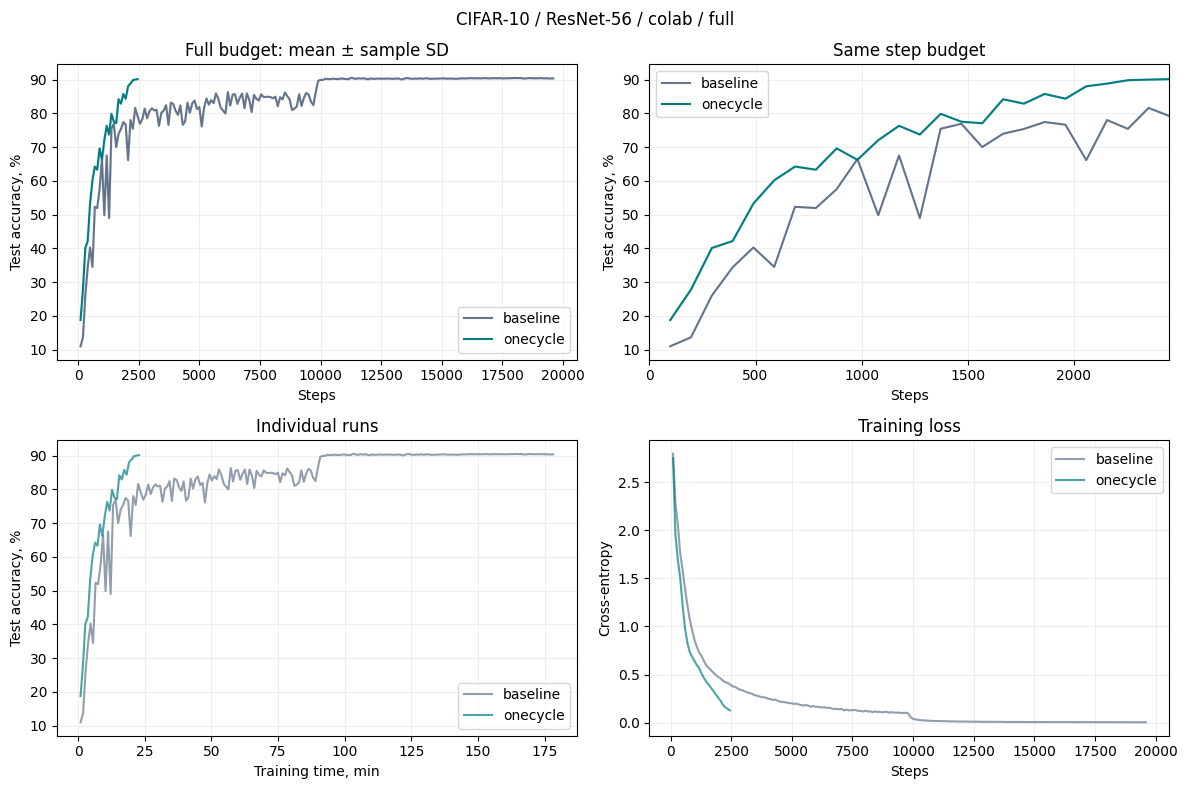

Архив CIFAR: /content/drive/MyDrive/EffNN/superconvergence_cifar10_v1/resnet56/colab/full_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
if CIFAR_RUN_TRAINING:
    cifar_final, cifar_summary, cifar_pairs = summarize_cifar(cifar_history, cifar_settings, CIFAR_SEEDS)
    display(cifar_summary.round(4))
    display(cifar_pairs.round(4))
    for name, table in (("final_results", cifar_final), ("summary", cifar_summary),
                        ("paired_comparisons", cifar_pairs)):
        table.to_csv(cifar_output_dir / f"{name}.csv", index=False)
    cifar_summary.to_json(cifar_output_dir / "summary.json", orient="records", indent=2)
    cifar_figure = plot_cifar_results(cifar_history, cifar_settings)
    cifar_figure.savefig(cifar_output_dir / "results.png", dpi=180)
    plt.show()
    plt.close(cifar_figure)

    cifar_html = f"""<!doctype html><html lang="ru"><meta charset="utf-8">
    <h1>CIFAR-10 / ResNet-{CIFAR_DEPTH} / {CIFAR_PROTOCOL} / {CIFAR_MODE}</h1>
    <p>Собственные измерения PyTorch, не точная копия Caffe. SD выборочное.
    Время не включает сохранение checkpoints и загрузку данных.</p>
    {cifar_summary.round(4).to_html(index=False)}
    {cifar_pairs.round(4).to_html(index=False)}
    <img src="schedules.png" style="max-width:100%">
    <img src="results.png" style="max-width:100%">
    </html>"""
    (cifar_output_dir / "results.html").write_text(cifar_html, encoding="utf-8")
    cifar_archive = shutil.make_archive(str(cifar_output_dir) + "_results", "zip", root_dir=cifar_output_dir)
    print("Архив CIFAR:", cifar_archive)
    if CIFAR_MODE == "smoke":
        print("SMOKE: результаты только проверяют код, не используйте их в отчёте о качестве.")
    if in_colab and DOWNLOAD_ZIP:
        from google.colab import files
        files.download(cifar_archive)
